In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': 'Computer Modern Roman',
    'text.usetex': True,
    'font.size': 9,
    'figure.figsize': (3.375, 2.8),
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'text.latex.preamble': r'\usepackage{physics}'
})

import alpaca
print(alpaca.__version__)

1.2.0


In [2]:
cG = alpaca.ALPcouplings({'cG': 1.0}, scale=5.0, basis='VA_below')

In [4]:
ma = np.logspace(-2, np.log10(3.0), 200)

sbtilde_lattice = 0.025
sbtilde_err = 0.031

sbp_2 = np.linspace(sbtilde_lattice - 2*sbtilde_err, sbtilde_lattice + 2*sbtilde_err, 50)


In [5]:
cpp_0 = [alpaca.effective_coupling(m, cG, 'proton proton', 'A', integrator='no_rge', sbtilde=sbtilde_lattice) for m in ma]
cnn_0 = [alpaca.effective_coupling(m, cG, 'neutron neutron', 'A', integrator='no_rge', sbtilde=sbtilde_lattice) for m in ma]

cpp = np.zeros((200, 50))
cnn = np.zeros((200, 50))

for i, m in enumerate(ma):
    for j, sb in enumerate(sbp_2):
        cpp[i, j] = alpaca.effective_coupling(m, cG, 'proton proton', 'A', integrator='no_rge', sbtilde=sb)
        cnn[i, j] = alpaca.effective_coupling(m, cG, 'neutron neutron', 'A', integrator='no_rge', sbtilde=sb)

max_cpp2 = np.max(cpp, axis=1)
min_cpp2 = np.min(cpp, axis=1)

max_cnn2 = np.max(cnn, axis=1)
min_cnn2 = np.min(cnn, axis=1)

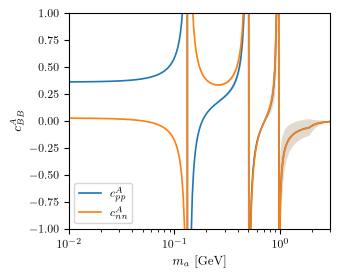

In [6]:
plt.semilogx(ma, cpp_0, label=r'$c_{pp}^A$')
plt.semilogx(ma, cnn_0, label=r'$c_{nn}^A$')
plt.fill_between(ma, min_cpp2, max_cpp2, color='tab:blue', alpha=0.15, linewidth=0)
plt.fill_between(ma, min_cnn2, max_cnn2, color='tab:orange', alpha=0.15, linewidth=0)

plt.ylim(-1, 1)
plt.xlim(1e-2, 3)
plt.legend(loc='lower left')
plt.xlabel(r'$m_a$ [GeV]')
plt.ylabel(r'$c_{BB}^A$')

plt.savefig('couplings_nucleons_SBprime.pdf', bbox_inches='tight', dpi=300)

In [7]:
cSigmapSigmap_0 = [alpaca.effective_coupling(m, cG, 'Sigma+ Sigma+', 'A', integrator='no_rge', sbtilde=sbtilde_lattice) for m in ma]
cSigma0Sigma0_0 = [alpaca.effective_coupling(m, cG, 'Sigma0 Sigma0', 'A', integrator='no_rge', sbtilde=sbtilde_lattice) for m in ma]
cSigmamSigmam_0 = [alpaca.effective_coupling(m, cG, 'Sigma- Sigma-', 'A', integrator='no_rge', sbtilde=sbtilde_lattice) for m in ma]

cSigmapSigmap = np.zeros((200, 50))
cSigma0Sigma0 = np.zeros((200, 50))
cSigmamSigmam = np.zeros((200, 50))

for i, m in enumerate(ma):
    for j, sb in enumerate(sbp_2):
        cSigmapSigmap[i, j] = alpaca.effective_coupling(m, cG, 'Sigma+ Sigma+', 'A', integrator='no_rge', sbtilde=sb)
        cSigma0Sigma0[i, j] = alpaca.effective_coupling(m, cG, 'Sigma0 Sigma0', 'A', integrator='no_rge', sbtilde=sb)
        cSigmamSigmam[i, j] = alpaca.effective_coupling(m, cG, 'Sigma- Sigma-', 'A', integrator='no_rge', sbtilde=sb)

max_cSigmapSigmap = np.max(cSigmapSigmap, axis=1)
min_cSigmapSigmap = np.min(cSigmapSigmap, axis=1)
max_cSigma0Sigma0 = np.max(cSigma0Sigma0, axis=1)
min_cSigma0Sigma0 = np.min(cSigma0Sigma0, axis=1)
max_cSigmamSigmam = np.max(cSigmamSigmam, axis=1)
min_cSigmamSigmam = np.min(cSigmamSigmam, axis=1)

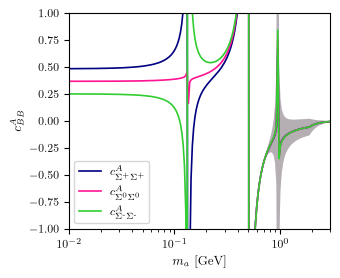

In [8]:
plt.semilogx(ma, cSigmapSigmap_0, label=r'$c_{\Sigma^+\Sigma^+}^A$', c='navy')
plt.semilogx(ma, cSigma0Sigma0_0, label=r'$c_{\Sigma^0\Sigma^0}^A$', c='deeppink')
plt.semilogx(ma, cSigmamSigmam_0, label=r'$c_{\Sigma^\text{-}\Sigma^\text{-}}^A$', c='limegreen')

plt.fill_between(ma, min_cSigmapSigmap, max_cSigmapSigmap, color='navy', alpha=0.2, linewidth=0)
plt.fill_between(ma, min_cSigma0Sigma0, max_cSigma0Sigma0, color='deeppink', alpha=0.2, linewidth=0)
plt.fill_between(ma, min_cSigmamSigmam, max_cSigmamSigmam, color='limegreen', alpha=0.2, linewidth=0)
plt.ylim(-1, 1)
plt.xlim(1e-2, 3)
plt.legend(loc='lower left')
plt.xlabel(r'$m_a$ [GeV]')
plt.ylabel(r'$c_{BB}^A$')
plt.savefig('couplings_sigmas_SBprime.pdf', bbox_inches='tight', dpi=300)

In [9]:
cXi0Xi0_0 = [alpaca.effective_coupling(m, cG, 'Xi0 Xi0', 'A', integrator='no_rge', sbtilde=sbtilde_lattice) for m in ma]
cXimXim_0 = [alpaca.effective_coupling(m, cG, 'Xi- Xi-', 'A', integrator='no_rge', sbtilde=sbtilde_lattice) for m in ma]

cXi0Xi0 = np.zeros((200, 50))
cXimXim = np.zeros((200, 50))

for i, m in enumerate(ma):
    for j, sb in enumerate(sbp_2):
        cXi0Xi0[i, j] = alpaca.effective_coupling(m, cG, 'Xi0 Xi0', 'A', integrator='no_rge', sbtilde=sb)
        cXimXim[i, j] = alpaca.effective_coupling(m, cG, 'Xi- Xi-', 'A', integrator='no_rge', sbtilde=sb)

max_cXi0Xi0 = np.max(cXi0Xi0, axis=1)
min_cXi0Xi0 = np.min(cXi0Xi0, axis=1)
max_cXimXim = np.max(cXimXim, axis=1)
min_cXimXim = np.min(cXimXim, axis=1)

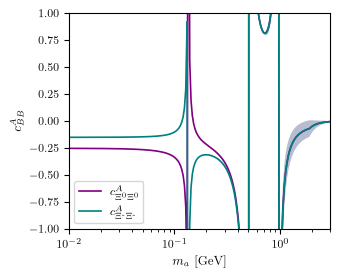

In [10]:
plt.semilogx(ma, cXi0Xi0_0, label=r'$c_{\Xi^0\Xi^0}^A$', c='purple')
plt.semilogx(ma, cXimXim_0, label=r'$c_{\Xi^\text{-}\Xi^\text{-}}^A$', c='teal')
plt.fill_between(ma, min_cXi0Xi0, max_cXi0Xi0, color='purple', alpha=0.2, linewidth=0)
plt.fill_between(ma, min_cXimXim, max_cXimXim, color='teal', alpha=0.2, linewidth=0)

plt.ylim(-1, 1)
plt.xlim(1e-2, 3)
plt.legend(loc='lower left')
plt.xlabel(r'$m_a$ [GeV]')
plt.ylabel(r'$c_{BB}^A$')
plt.savefig('couplings_xis_SBprime.pdf', bbox_inches='tight', dpi=300)

In [11]:
cLambdaLambda_0 = [alpaca.effective_coupling(m, cG, 'Lambda Lambda', 'A', integrator='no_rge', sbtilde=sbtilde_lattice) for m in ma]
cLambdaSigma0_0 = [alpaca.effective_coupling(m, cG, 'Lambda Sigma0', 'A', integrator='no_rge', sbtilde=sbtilde_lattice) for m in ma]

cLambdaLambda = np.zeros((200, 50))

for i, m in enumerate(ma):
    for j, sb in enumerate(sbp_2):
        cLambdaLambda[i, j] = alpaca.effective_coupling(m, cG, 'Lambda Lambda', 'A', integrator='no_rge', sbtilde=sb)

max_cLambdaLambda = np.max(cLambdaLambda, axis=1)
min_cLambdaLambda = np.min(cLambdaLambda, axis=1)

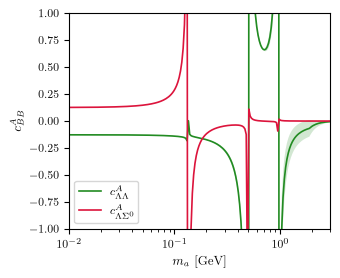

In [12]:
plt.semilogx(ma, cLambdaLambda_0, label=r'$c_{\Lambda\Lambda}^A$', c='forestgreen')
plt.semilogx(ma, cLambdaSigma0_0, label=r'$c_{\Lambda\Sigma^0}^A$', c='crimson')
plt.fill_between(ma, min_cLambdaLambda, max_cLambdaLambda, color='forestgreen', alpha=0.2, linewidth=0)

plt.ylim(-1, 1)
plt.xlim(1e-2, 3)
plt.legend(loc='lower left')
plt.xlabel(r'$m_a$ [GeV]')
plt.ylabel(r'$c_{BB}^A$')
plt.savefig('couplings_lambdas_SBprime.pdf', bbox_inches='tight', dpi=300)

In [13]:
lfv = np.array([[0,1,0], [1,0,0], [0,0,0]])*2.0 # Different normalization in ALP-aca vs paper

cds = alpaca.ALPcouplings({'cdA': lfv, 'cdV': lfv}, scale=5.0, basis='VA_below')

In [14]:
cpSigmap_A = [alpaca.effective_coupling(m, cds, 'Sigma+ proton', 'A', integrator='no_rge') for m in ma]
cnSigma0_A = [alpaca.effective_coupling(m, cds, 'Sigma0 neutron', 'A', integrator='no_rge') for m in ma]
cnLambda_A = [alpaca.effective_coupling(m, cds, 'Lambda neutron', 'A', integrator='no_rge') for m in ma]


In [15]:
cpSigmap_V = [alpaca.effective_coupling(m, cds, 'Sigma+ proton', 'V', integrator='no_rge') for m in ma]
cnSigma0_V = [alpaca.effective_coupling(m, cds, 'Sigma0 neutron', 'V', integrator='no_rge') for m in ma]
cnLambda_V = [alpaca.effective_coupling(m, cds, 'Lambda neutron', 'V', integrator='no_rge') for m in ma]

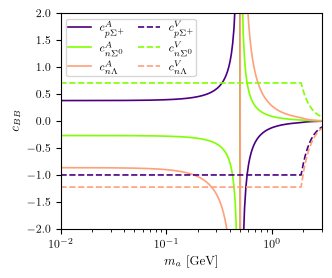

In [16]:
plt.semilogx(ma, cpSigmap_A, label=r'$c_{p \Sigma^+}^A$', c='indigo')
plt.semilogx(ma, cnSigma0_A, label=r'$c_{n \Sigma^0}^A$', c='chartreuse')
plt.semilogx(ma, cnLambda_A, label=r'$c_{n \Lambda}^A$', c='lightsalmon')

plt.semilogx(ma, cpSigmap_V, label=r'$c_{p \Sigma^+}^V$', c='indigo', ls='--')
plt.semilogx(ma, cnSigma0_V, label=r'$c_{n \Sigma^0}^V$', c='chartreuse', ls='--')
plt.semilogx(ma, cnLambda_V, label=r'$c_{n \Lambda}^V$', c='lightsalmon', ls='--')

plt.ylim(-2, 2)
plt.xlim(1e-2, 3)
plt.legend(ncol=2, borderpad=0.2, labelspacing=0.4, columnspacing=1.2)
plt.xlabel(r'$m_a$ [GeV]')
plt.ylabel(r'$c_{BB}$')
plt.savefig('coupling_lfv_nucleons.pdf', bbox_inches='tight', dpi=300)

In [17]:
cSigma0Xi0_A = [alpaca.effective_coupling(m, cds, 'Sigma0 Xi0', 'A', integrator='no_rge') for m in ma]
cSigmamXim_A = [alpaca.effective_coupling(m, cds, 'Sigma- Xi-', 'A', integrator='no_rge') for m in ma]
cLambdaXi0_A = [alpaca.effective_coupling(m, cds, 'Lambda Xi0', 'A', integrator='no_rge') for m in ma]

In [18]:
cSigma0Xi0_V = [alpaca.effective_coupling(m, cds, 'Sigma0 Xi0', 'V', integrator='no_rge') for m in ma]
cSigmamXim_V = [alpaca.effective_coupling(m, cds, 'Sigma- Xi-', 'V', integrator='no_rge') for m in ma]
cLambdaXi0_V = [alpaca.effective_coupling(m, cds, 'Lambda Xi0', 'V', integrator='no_rge') for m in ma]

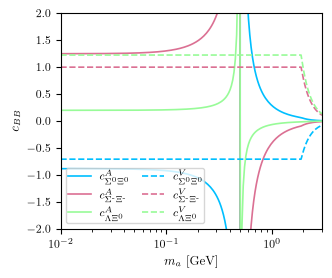

In [19]:
plt.semilogx(ma, cSigma0Xi0_A, label=r'$c_{\Sigma^0 \Xi^0}^A$', c='deepskyblue')
plt.semilogx(ma, cSigmamXim_A, label=r'$c_{\Sigma^\text{-} \Xi^\text{-}}^A$', c='palevioletred')
plt.semilogx(ma, cLambdaXi0_A, label=r'$c_{\Lambda \Xi^0}^A$', c='palegreen')

plt.semilogx(ma, cSigma0Xi0_V, label=r'$c_{\Sigma^0 \Xi^0}^V$', c='deepskyblue', ls='--')
plt.semilogx(ma, cSigmamXim_V, label=r'$c_{\Sigma^\text{-} \Xi^\text{-}}^V$', c='palevioletred', ls='--')
plt.semilogx(ma, cLambdaXi0_V, label=r'$c_{\Lambda \Xi^0}^V$', c='palegreen', ls='--')

plt.ylim(-2, 2)
plt.xlim(1e-2, 3)
plt.legend(ncol=2, borderpad=0.2, labelspacing=0.4, columnspacing=1.2, loc='lower left')
plt.xlabel(r'$m_a$ [GeV]')
plt.ylabel(r'$c_{BB}$')
plt.savefig('coupling_lfv_hyperons.pdf', bbox_inches='tight', dpi=300)